# INF201 – Deliverable 1: Værdata fra Ås

**Gruppe**: Torjus Westhagen-Fladset og Eirik Nysveen

**GitHub**: https://github.com/Sommerogsol123/inf201-deliverable1

Data er hentet fra Meteorologisk institutt via Frost API (frost.met.no). Stasjon data er hentet fra: SN17850 (Ås).
Funksjonen for å hente data bygger på METs Python-eksempel (https://frost.met.no/python_example.html), men er skrevet om.

In [1]:
import requests
import pandas as pd
from pathlib import Path

ENDPOINT = "https://frost.met.no/observations/v0.jsonld"
STATION = "SN17850"  # Ås


def read_client_id(path="frost_client_id.txt"):
    """Leser client-ID fra en lokal fil som ikke ligger i Git."""
    return Path(path).read_text().strip()


CLIENT_ID = read_client_id()


def fetch_frost(source, element, referencetime, client_id=CLIENT_ID):
    """Henter observasjoner fra Frost og returnerer dem som en DataFrame."""
    parameters = {
        "sources": source,
        "elements": element,
        "referencetime": referencetime,
    }
    response = requests.get(ENDPOINT, params=parameters, auth=(client_id, ""), timeout=30)
    data = response.json()

    if response.status_code != 200:
        error = data.get("error", {})
        raise RuntimeError(
            f"Frost svarte med feil {response.status_code}: "
            f"{error.get('message')} ({error.get('reason')})"
        )

    rows = []
    for item in data["data"]:
        for obs in item["observations"]:
            rows.append({
                "referenceTime": item["referenceTime"],
                "value": obs["value"],
                "unit": obs.get("unit"),
                "timeOffset": obs.get("timeOffset"),
            })

    df = pd.DataFrame(rows)
    df["referenceTime"] = pd.to_datetime(df["referenceTime"])
    return df

In [2]:
temp_raw = fetch_frost(STATION, "mean(air_temperature P1D)", "2025-01-01/2025-12-31")

print(temp_raw.head())
print("Antall rader:", len(temp_raw))
print(temp_raw["timeOffset"].value_counts())

              referenceTime  value  unit timeOffset
0 2025-01-01 00:00:00+00:00   -5.2  degC       PT0H
1 2025-01-01 00:00:00+00:00   -2.8  degC       PT6H
2 2025-01-02 00:00:00+00:00  -11.5  degC       PT0H
3 2025-01-02 00:00:00+00:00   -7.2  degC       PT6H
4 2025-01-03 00:00:00+00:00   -8.9  degC       PT0H
Antall rader: 728
timeOffset
PT0H    364
PT6H    364
Name: count, dtype: int64


In [3]:
def to_daily_series(df, time_offset="PT0H"):
    """Velger én timeOffset og returnerer en tidsserie med én verdi per dag."""
    selected = df[df["timeOffset"] == time_offset]
    series = selected.set_index("referenceTime")["value"]
    series.index = series.index.tz_localize(None)
    return series.sort_index()


temp_raw = fetch_frost(STATION, "mean(air_temperature P1D)", "2025-01-01/2026-01-01")
temp_2025 = to_daily_series(temp_raw, "PT0H")

all_days = pd.date_range("2025-01-01", "2025-12-31")
missing = all_days.difference(temp_2025.index)

print("Antall dager:", len(temp_2025))
print("Første dag:", temp_2025.index.min().date(), "| Siste dag:", temp_2025.index.max().date())
print("Manglende dager:", len(missing))

Antall dager: 365
Første dag: 2025-01-01 | Siste dag: 2025-12-31
Manglende dager: 0


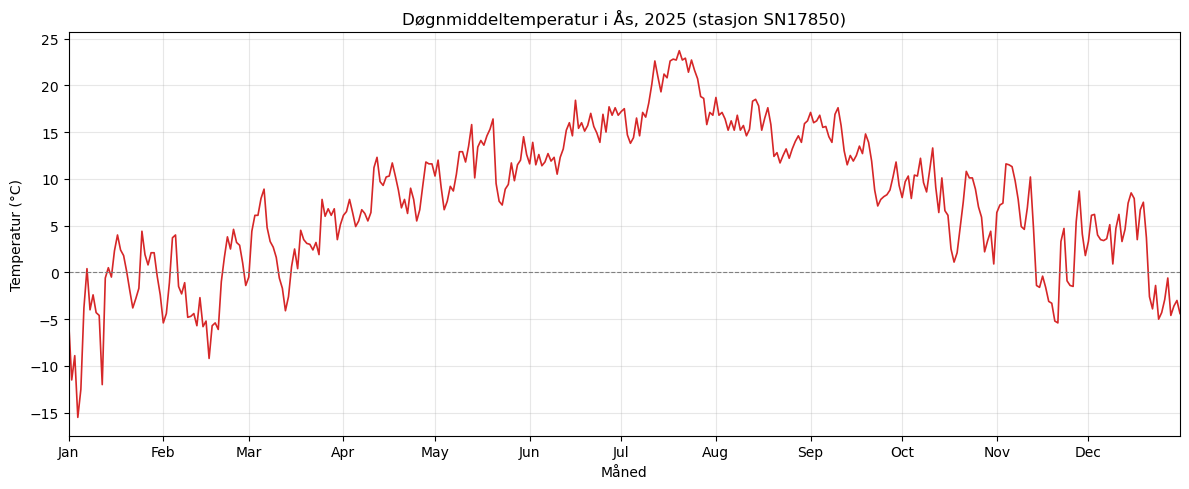

In [4]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(temp_2025.index, temp_2025.values, color="tab:red", linewidth=1.2)
ax.axhline(0, color="grey", linewidth=0.8, linestyle="--")

ax.set_title("Døgnmiddeltemperatur i Ås, 2025 (stasjon SN17850)")
ax.set_xlabel("Måned")
ax.set_ylabel("Temperatur (°C)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_xlim(temp_2025.index.min(), temp_2025.index.max())
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

In [5]:
def summary_table(series_dict):
    """Lager en tabell med gjennomsnitt, median, min og maks for én eller flere tidsserier."""
    table = pd.DataFrame({
        name: {
            "Gjennomsnitt": series.mean(),
            "Median": series.median(),
            "Min": series.min(),
            "Maks": series.max(),
        }
        for name, series in series_dict.items()
    })
    table.index.name = "Temperatur (°C)"
    return table.round(1)


print(summary_table({"2025": temp_2025}).to_string())

                 2025
Temperatur (°C)      
Gjennomsnitt      7.9
Median            8.3
Min             -15.5
Maks             23.7


# Oppgave 1: Diskusjon

Vi hentet døgnmiddeltemperatur for Ås i 2025. To ting måtte håndteres underveis:

- Frost returnerer to verdier per dag, med `timeOffset` PT0H og PT6H. PT0H er døgnet fra midnatt til midnatt (UTC),
  mens PT6H regner døgnet fra kl. 06 til 06. Vi brukte PT0H, som tilsvarer en vanlig kalenderdag.
- Sluttdatoen i `referencetime` er ikke inkludert. Med `2025-12-31` som slutt fikk vi bare 364 dager,
  så vi brukte `2026-01-01` for å få med 31. desember. Resultatet er 365 dager uten hull.

Plottet viser en tydelig årssyklus. Den kaldeste dagen var −15,5 °C i starten av januar, og den varmeste
var 23,7 °C i slutten av juli. Medianen (8,3 °C) er litt høyere enn gjennomsnittet (7,9 °C), fordi noen
svært kalde vinterdager trekker gjennomsnittet ned.

In [6]:
precip_raw = fetch_frost(STATION, "sum(precipitation_amount P1D)", "2025-01-01/2026-01-01")

print(precip_raw.head())
print("Antall rader:", len(precip_raw))
print(precip_raw["timeOffset"].value_counts())

              referenceTime  value unit timeOffset
0 2025-01-01 00:00:00+00:00    5.4   mm      PT18H
1 2025-01-01 00:00:00+00:00    6.6   mm       PT6H
2 2025-01-02 00:00:00+00:00    0.0   mm      PT18H
3 2025-01-02 00:00:00+00:00    1.9   mm       PT6H
4 2025-01-03 00:00:00+00:00    0.1   mm      PT18H
Antall rader: 730
timeOffset
PT18H    365
PT6H     365
Name: count, dtype: int64


In [7]:
precip_2025 = to_daily_series(precip_raw, "PT6H")

print("Antall dager:", len(precip_2025))
print("Total nedbør 2025:", round(precip_2025.sum(), 1), "mm")
print("Dager med nedbør (> 0 mm):", (precip_2025 > 0).sum())

Antall dager: 365
Total nedbør 2025: 950.2 mm
Dager med nedbør (> 0 mm): 184


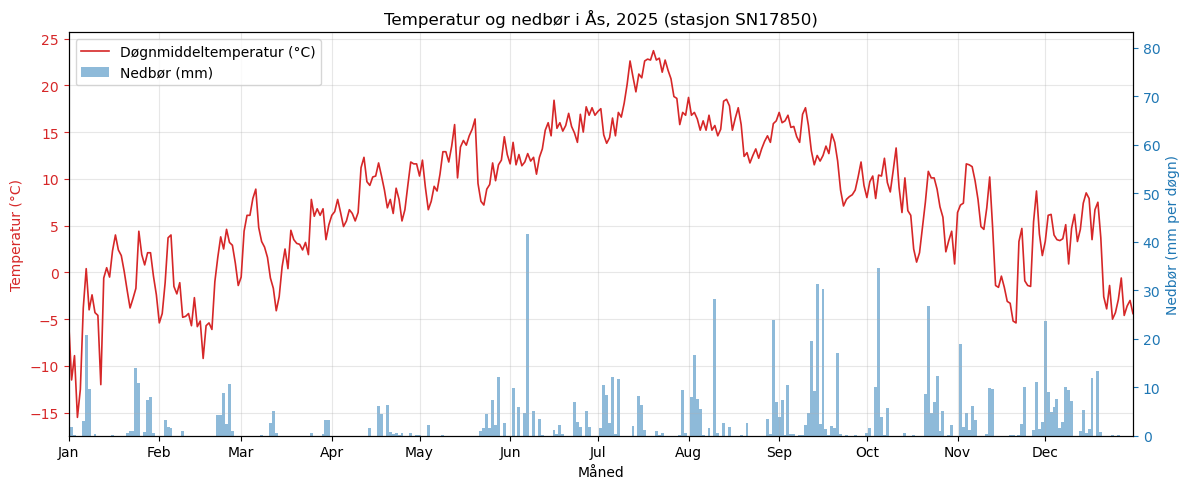

In [8]:
fig, ax_temp = plt.subplots(figsize=(12, 5))
ax_precip = ax_temp.twinx()

ax_precip.bar(precip_2025.index, precip_2025.values, width=1.0,
              color="tab:blue", alpha=0.5, label="Nedbør (mm)")
ax_temp.plot(temp_2025.index, temp_2025.values, color="tab:red",
             linewidth=1.2, label="Døgnmiddeltemperatur (°C)")

ax_temp.set_zorder(ax_precip.get_zorder() + 1)
ax_temp.patch.set_visible(False)

ax_temp.set_title("Temperatur og nedbør i Ås, 2025 (stasjon SN17850)")
ax_temp.set_xlabel("Måned")
ax_temp.set_ylabel("Temperatur (°C)", color="tab:red")
ax_precip.set_ylabel("Nedbør (mm per døgn)", color="tab:blue")
ax_temp.tick_params(axis="y", colors="tab:red")
ax_precip.tick_params(axis="y", colors="tab:blue")

ax_precip.set_ylim(0, precip_2025.max() * 2)

ax_temp.xaxis.set_major_locator(mdates.MonthLocator())
ax_temp.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax_temp.set_xlim(temp_2025.index.min(), temp_2025.index.max())
ax_temp.grid(alpha=0.3)

temp_handles, temp_labels = ax_temp.get_legend_handles_labels()
precip_handles, precip_labels = ax_precip.get_legend_handles_labels()
ax_temp.legend(temp_handles + precip_handles, temp_labels + precip_labels, loc="upper left")

fig.tight_layout()
plt.show()

## Oppgave 2: Diskusjon

Vi hentet døgnnedbør (`sum(precipitation_amount P1D)`) for Ås i 2025. Også her returnerer Frost to verdier per dag,
med `timeOffset` PT6H og PT18H. Vi brukte PT6H, som er METs standard nedbørsdøgn (kl. 06–06 UTC).
Det betyr at nedbørsdøgnet er forskjøvet seks timer i forhold til temperaturdøgnet (00–00), men over et helt år
har dette liten betydning for plottet. Totalt falt det 950,2 mm nedbør i 2025, fordelt på 184 dager med nedbør.

**Valg av plot:**
- Temperatur og nedbør har ulike enheter og skalaer, så vi brukte to y-akser: temperatur til venstre og nedbør til høyre.
- Temperatur vises som linje, fordi den endrer seg gradvis fra dag til dag.
- Nedbør vises som søyler, fordi det er en mengde som samles opp per døgn, og mange dager har 0 mm.
  En linje ville gitt inntrykk av nedbør mellom regndagene.
- Søylene er begrenset til den nedre delen av plottet og ligger bak temperaturlinjen, slik at begge er lette å lese.
- Fargene (rødt for temperatur, blått for nedbør) går igjen på aksene, slik at det er tydelig hvilken akse som hører til hva.

Plottet viser at den største nedbørsdagen kom i starten av juni (rundt 40 mm), og at høsten hadde flere
dager med mye nedbør. Våren var relativt tørr.

In [9]:
temp_1925_raw = fetch_frost(STATION, "mean(air_temperature P1D)", "1925-01-01/1926-01-01")

print(temp_1925_raw.head())
print("Antall rader:", len(temp_1925_raw))
print(temp_1925_raw["timeOffset"].value_counts())

              referenceTime  value  unit timeOffset
0 1925-01-01 00:00:00+00:00    1.3  degC       PT0H
1 1925-01-02 00:00:00+00:00    4.1  degC       PT0H
2 1925-01-03 00:00:00+00:00    2.1  degC       PT0H
3 1925-01-04 00:00:00+00:00    0.1  degC       PT0H
4 1925-01-05 00:00:00+00:00   -2.2  degC       PT0H
Antall rader: 365
timeOffset
PT0H    365
Name: count, dtype: int64


In [10]:
temp_1925 = to_daily_series(temp_1925_raw, "PT0H")

all_days_1925 = pd.date_range("1925-01-01", "1925-12-31")
missing_1925 = all_days_1925.difference(temp_1925.index)

print("Antall dager:", len(temp_1925))
print("Første dag:", temp_1925.index.min().date(), "| Siste dag:", temp_1925.index.max().date())
print("Manglende dager:", len(missing_1925))

Antall dager: 365
Første dag: 1925-01-01 | Siste dag: 1925-12-31
Manglende dager: 0


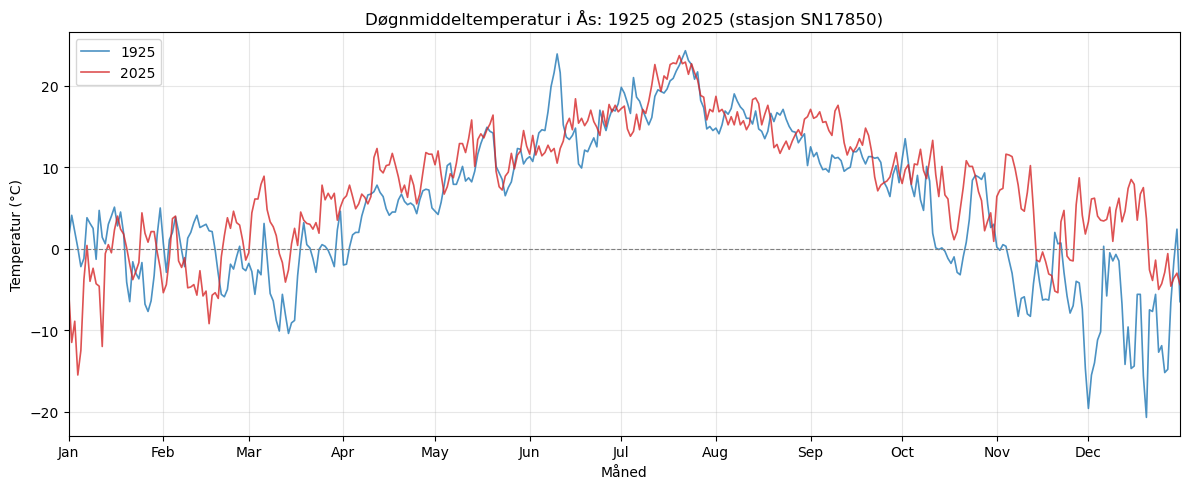

In [11]:
temp_1925_shifted = temp_1925.copy()
temp_1925_shifted.index = temp_1925_shifted.index + pd.DateOffset(years=100)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(temp_1925_shifted.index, temp_1925_shifted.values, color="tab:blue",
        linewidth=1.2, alpha=0.8, label="1925")
ax.plot(temp_2025.index, temp_2025.values, color="tab:red",
        linewidth=1.2, alpha=0.8, label="2025")
ax.axhline(0, color="grey", linewidth=0.8, linestyle="--")

ax.set_title("Døgnmiddeltemperatur i Ås: 1925 og 2025 (stasjon SN17850)")
ax.set_xlabel("Måned")
ax.set_ylabel("Temperatur (°C)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_xlim(temp_2025.index.min(), temp_2025.index.max())
ax.grid(alpha=0.3)
ax.legend(loc="upper left")

fig.tight_layout()
plt.show()

In [12]:
comparison = summary_table({"1925": temp_1925, "2025": temp_2025})
comparison["Forskjell (2025 − 1925)"] = (comparison["2025"] - comparison["1925"]).round(1)

print(comparison.to_string())

                 1925  2025  Forskjell (2025 − 1925)
Temperatur (°C)                                     
Gjennomsnitt      5.3   7.9                      2.6
Median            5.3   8.3                      3.0
Min             -20.7 -15.5                      5.2
Maks             24.3  23.7                     -0.6


## Oppgave 3: Diskusjon

Vi hentet døgnmiddeltemperatur for Ås i 1925 og sammenlignet med 2025. For 1925 fant Frost bare én versjon
per dag (`timeOffset` PT0H), og alle 365 dager var med. Vi brukte PT0H for begge årene, slik at vi sammenligner samme type døgn.
For å plotte årene oppå hverandre flyttet vi datoene for 1925 hundre år fram (`pd.DateOffset(years=100)`),
slik at samme dag i året havner på samme sted på x-aksen.

2025 var i gjennomsnitt 2,6 °C varmere enn 1925, og medianen var 3,0 °C høyere. Forskjellen var størst om vinteren:
Den kaldeste dagen i 2025 var 5,2 °C mildere enn i 1925, og november og desember 1925 var mye kaldere enn i 2025.
Somrene var derimot ganske like, og den varmeste dagen var faktisk litt varmere i 1925 (24,3 °C) enn i 2025 (23,7 °C).
Våren 2025 var varmere enn i 1925, mens januar 2025 hadde noen av de kaldeste dagene i starten av året.

**Forbehold:** Vi sammenligner bare to enkeltår, og temperaturen varierer mye fra år til år. Resultatet alene
viser altgså ikke en langsiktig trend, men det er i tråd med at det har blitt varmere i Norge det siste hundreåret.
I tillegg har målemetodene endret seg: I 1925 ble temperaturen avlest manuelt noen få ganger i døgnet,
mens den i dag måles automatisk. Døgnmiddelet er derfor ikke beregnet på nøyaktig samme måte i de to årene.

In [13]:
tmax_raw = fetch_frost(STATION, "max(air_temperature P1D)", "2025-01-01/2026-01-01")

print(tmax_raw.head())
print("Antall rader:", len(tmax_raw))
print(tmax_raw["timeOffset"].value_counts())

              referenceTime  value  unit timeOffset
0 2025-01-01 00:00:00+00:00   -3.4  degC       PT0H
1 2025-01-01 00:00:00+00:00   -3.0  degC      PT18H
2 2025-01-02 00:00:00+00:00   -5.2  degC       PT0H
3 2025-01-02 00:00:00+00:00   -5.2  degC      PT18H
4 2025-01-03 00:00:00+00:00   -1.4  degC       PT0H
Antall rader: 729
timeOffset
PT18H    365
PT0H     364
Name: count, dtype: int64


In [14]:
tmax_2025 = to_daily_series(tmax_raw, "PT18H")
hot_days = tmax_2025[tmax_2025 >= 27]

print("Antall dager:", len(tmax_2025))
print("Dager med maks ≥ 27 °C:", len(hot_days))
print(hot_days)

Antall dager: 365
Dager med maks ≥ 27 °C: 11
referenceTime
2025-07-11    28.0
2025-07-12    28.1
2025-07-16    28.3
2025-07-17    29.5
2025-07-18    30.1
2025-07-19    29.9
2025-07-20    30.8
2025-07-21    28.6
2025-07-22    28.4
2025-07-24    29.4
2025-07-25    27.6
Name: value, dtype: float64


In [15]:
def find_heatwaves(tmax, threshold=27, min_days=5):
    """Finner perioder med minst min_days dager på rad der maks-temperaturen er >= threshold.

    Returnerer en liste med (startdato, sluttdato) for hver hetebølge.
    """
    hot_dates = tmax[tmax >= threshold].index
    heatwaves = []
    run = []

    for date in hot_dates:
        if run and (date - run[-1]).days == 1:
            run.append(date)
        else:
            if len(run) >= min_days:
                heatwaves.append((run[0], run[-1]))
            run = [date]

    if len(run) >= min_days:
        heatwaves.append((run[0], run[-1]))

    return heatwaves


heatwaves_2025 = find_heatwaves(tmax_2025)
print("Antall hetebølger:", len(heatwaves_2025))
for start, end in heatwaves_2025:
    print(start.date(), "-", end.date())

Antall hetebølger: 1
2025-07-16 - 2025-07-22


In [16]:
import yaml


def count_heatwaves(station_id, station_name, year, threshold=27, min_days=5, filename=None):
    """Teller hetebølger for en stasjon og et år, og skriver en oppsummering til en yml-fil.

    Returnerer antall hetebølger.
    """
    raw = fetch_frost(station_id, "max(air_temperature P1D)", f"{year}-01-01/{year + 1}-01-01")

    offsets = raw["timeOffset"].value_counts()
    time_offset = "PT18H" if "PT18H" in offsets.index else offsets.index[0]
    tmax = to_daily_series(raw, time_offset)

    heatwaves = find_heatwaves(tmax, threshold, min_days)

    summary = {
        "dates": [f"{start.date()} - {end.date()}" for start, end in heatwaves],
        "station_id": station_id,
        "station_name": station_name,
        "year": year,
    }

    if filename is None:
        filename = f"heatwaves_{station_id}_{year}.yml"

    with open(filename, "w") as file:
        yaml.dump(summary, file)

    return len(heatwaves)


n = count_heatwaves("SN17850", "Ås", 2025)
print("Antall hetebølger:", n)
print()
print(Path("heatwaves_SN17850_2025.yml").read_text())

Antall hetebølger: 1

dates:
- 2025-07-16 - 2025-07-22
station_id: SN17850
station_name: "\xC5s"
year: 2025



In [17]:
test_cases = [
    ("SN18700", "Oslo - Blindern", 2018),
    ("SN17850", "Ås", 2018),
    ("SN17850", "Ås", 1925),
]

for station_id, station_name, year in test_cases:
    try:
        n = count_heatwaves(station_id, station_name, year)
        print(f"{station_name} ({station_id}), {year}: {n} hetebølge(r)")
        print(Path(f"heatwaves_{station_id}_{year}.yml").read_text())
    except RuntimeError as error:
        print(f"{station_name} ({station_id}), {year}: kunne ikke hente data – {error}")
        print()

Oslo - Blindern (SN18700), 2018: 2 hetebølge(r)
dates:
- 2018-05-29 - 2018-06-03
- 2018-07-15 - 2018-07-28
station_id: SN18700
station_name: Oslo - Blindern
year: 2018

Ås (SN17850), 2018: 1 hetebølge(r)
dates:
- 2018-05-29 - 2018-06-03
station_id: SN17850
station_name: "\xC5s"
year: 2018

Ås (SN17850), 1925: kunne ikke hente data – Frost svarte med feil 412: 412 (No time series found for this combination of parameters, check /observations/availableTimeSeries for more information.)



## Oppgave 4: Diskusjon

En hetebølge er definert som minst fem dager på rad der maksimumstemperaturen er 27 °C eller høyere.
Vi hentet døgnets maksimumstemperatur (`max(air_temperature P1D)`). Frost returnerer to versjoner,
med `timeOffset` PT18H (365 dager) og PT0H (364 dager). Vi brukte PT18H, som er METs standard for
maksimumstemperatur (døgnet regnes fra kl. 18 til 18 UTC) og har data for alle dager.

Vi delte løsningen i to funksjoner:
- `find_heatwaves` går gjennom dagene med minst 27 °C og samler dem i sammenhengende perioder.
  Den sjekker at datoene faktisk følger etter hverandre, slik at en manglende dag bryter perioden.
  Perioder på minst fem dager lagres som hetebølger.
- `count_heatwaves` henter data for en valgfri stasjon og et valgfritt år, finner hetebølgene,
  skriver en oppsummering til en yml-fil i samme format som eksempelfila, og returnerer antallet.
  Hvis stasjonen ikke har PT18H, bruker funksjonen den vanligste `timeOffset` i stedet.

**Resultater:** Ås hadde én hetebølge i 2025, fra 16. til 22. juli. For å vise at funksjonen virker
generelt, testet vi den også på andre stasjoner og år. Blindern hadde to hetebølger i 2018
(29. mai–3. juni og 15.–28. juli), mens Ås samme år bare hadde den første. For Ås i 1925 finnes
ikke maksimumstemperatur i Frost, og funksjonen ga da en tydelig feilmelding i stedet for å krasje.

Merk at eksempelfila bare viser formatet. Datoene i den stemmer ikke med de faktiske dataene for Ås i 2025.

In [18]:
def moving_average(series, window=7):
    """Beregner glidende gjennomsnitt over `window` dager, sentrert på hver dag."""
    return series.rolling(window=window, center=True).mean()


temp_2025_ma7 = moving_average(temp_2025)

print(temp_2025_ma7.head(10))
print()

manual = temp_2025.iloc[0:7].mean()
print("Manuelt gjennomsnitt av 1.–7. januar:", round(manual, 2))
print("Funksjonens verdi for 4. januar:     ", round(temp_2025_ma7.iloc[3], 2))

referenceTime
2025-01-01         NaN
2025-01-02         NaN
2025-01-03         NaN
2025-01-04   -8.142857
2025-01-05   -7.971429
2025-01-06   -6.671429
2025-01-07   -6.014286
2025-01-08   -4.457143
2025-01-09   -4.385714
2025-01-10   -3.928571
Name: value, dtype: float64

Manuelt gjennomsnitt av 1.–7. januar: -8.14
Funksjonens verdi for 4. januar:      -8.14


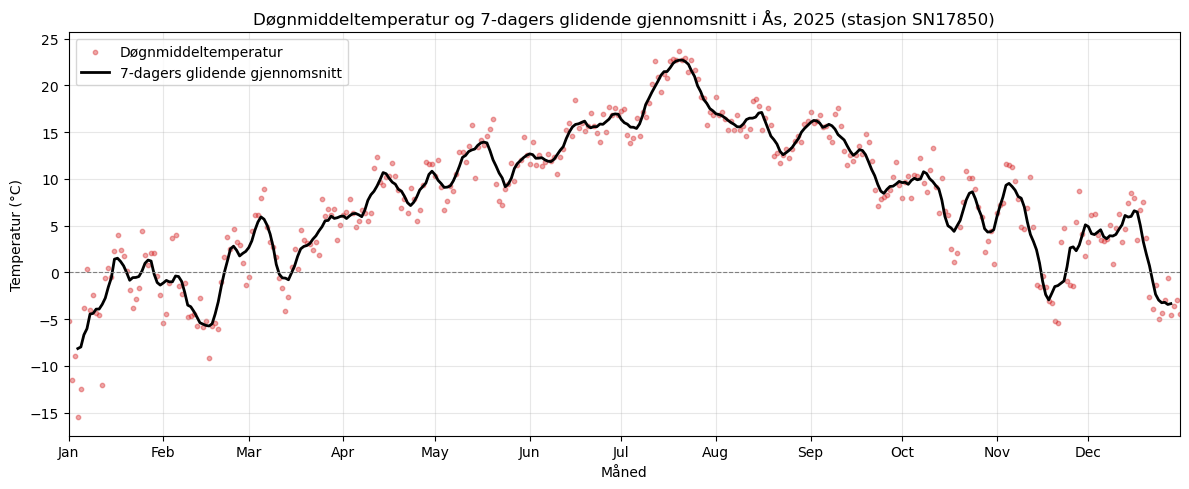

In [19]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.scatter(temp_2025.index, temp_2025.values, s=10, color="tab:red",
           alpha=0.4, label="Døgnmiddeltemperatur")
ax.plot(temp_2025_ma7.index, temp_2025_ma7.values, color="black",
        linewidth=2, label="7-dagers glidende gjennomsnitt")
ax.axhline(0, color="grey", linewidth=0.8, linestyle="--")

ax.set_title("Døgnmiddeltemperatur og 7-dagers glidende gjennomsnitt i Ås, 2025 (stasjon SN17850)")
ax.set_xlabel("Måned")
ax.set_ylabel("Temperatur (°C)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_xlim(temp_2025.index.min(), temp_2025.index.max())
ax.grid(alpha=0.3)
ax.legend(loc="upper left")

fig.tight_layout()
plt.show()

## Oppgave 5: Diskusjon

Funksjonen `moving_average` beregner glidende gjennomsnitt med pandas `rolling`. Vinduet er 7 dager og sentrert,
altså tre dager før, selve dagen og tre dager etter, slik at kurven ikke forskyves i tid. Vi kontrollerte funksjonen
ved å regne ut gjennomsnittet av 1.–7. januar for hånd. Det ga −8,14 °C, det samme som funksjonens verdi for 4. januar.
De tre første og tre siste dagene får ingen verdi, fordi vinduet der ikke har nok nabodager.

I plottet vises de daglige temperaturene som punkter og det glidende gjennomsnittet som linje.
Gjennomsnittet jevner ut de store svingningene fra dag til dag, slik at årssyklusen og lengre kalde og varme
perioder blir tydeligere, for eksempel kulden i starten av januar og varmetoppen i slutten av juli.